# Лабораторна робота №1. Лінійна регресія, оптимізація та статистичний аналіз

**Виконав:** Литвин Юрій, група ФЕІ-46с

**Мета:** зрозуміти архітектуру лінійної регресії, самостійно реалізувати алгоритми оптимізації, обрати інформативні ознаки, обчислити метрики якості та перевірити статистичні припущення моделі.

**Датасет:** House Prices: Advanced Regression Techniques (Kaggle, спрощена версія Ames Housing), файл `data/train.csv`. Цільова змінна `SalePrice`.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

SEED = 42
plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 30)

df = pd.read_csv('data/train.csv')
print('Розмір датасету:', df.shape)
df.head()

Розмір датасету: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,...,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,...,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,...,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,...,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Етап 1. Дослідження даних (EDA), відбір ознак та попередня обробка

### 1.1 Первинний аналіз даних

Спочатку дивимося на типи ознак і пропущені значення.

In [2]:
print('Типи стовпців:', df.dtypes.value_counts().to_dict())

missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({'пропусків': missing, '%': (100 * missing / len(df)).round(1)})

Типи стовпців: {dtype('O'): 43, dtype('int64'): 35, dtype('float64'): 3}


,пропусків,%
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageType,81,5.5
GarageYrBlt,81,5.5
GarageFinish,81,5.5


Датасет містить 1460 будинків і 81 стовпець: `Id`, цільову `SalePrice`, 36 числових ознак і 43 категоріальні (текстові).

Пропуски є у 19 стовпцях, але здебільшого це не втрачені дані. За описом датасету `NA` у `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu` означає "басейну / паркану / каміна немає", 81 пропуск у групі `Garage*` відповідає 81 будинку без гаража, а в `MasVnrType` значення `None` ("облицювання немає") pandas теж читає як пропуск. Справжні пропуски є в `LotFrontage` (17.7%), `MasVnrArea` (8 будинків) і `Electrical` (1). Ознаки, які ми далі відберемо, пропусків у цьому файлі не мають, але на випадок нових даних код заповнює їх медіаною з Train.

count      1460.0
mean     180921.0
std       79443.0
min       34900.0
25%      129975.0
50%      163000.0
75%      214000.0
max      755000.0
Name: SalePrice, dtype: float64
Асиметрія SalePrice: 1.88
Асиметрія log(1 + SalePrice): 0.12


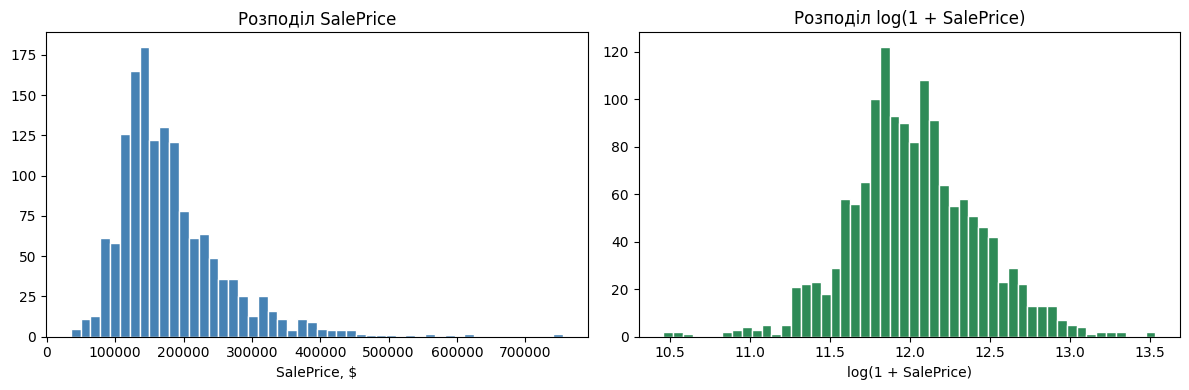

In [3]:
print(df['SalePrice'].describe().round(0))
print('Асиметрія SalePrice:', round(df['SalePrice'].skew(), 2))
print('Асиметрія log(1 + SalePrice):', round(np.log1p(df['SalePrice']).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df['SalePrice'], bins=50, color='steelblue', edgecolor='white')
ax[0].set_title('Розподіл SalePrice')
ax[0].set_xlabel('SalePrice, $')
ax[1].hist(np.log1p(df['SalePrice']), bins=50, color='seagreen', edgecolor='white')
ax[1].set_title('Розподіл log(1 + SalePrice)')
ax[1].set_xlabel('log(1 + SalePrice)')
plt.tight_layout()
plt.show()

Ціна від 34 900 до 755 000 \$, медіана 163 000 \$, середнє 180 921 \$. Розподіл сильно скошений вправо (асиметрія 1.88): більшість будинків відносно дешеві, а кілька дорогих утворюють довгий хвіст. Після перетворення $\log(1 + SalePrice)$ асиметрія 0.12, і розподіл близький до нормального.

Тому модель навчаємо на `LogPrice` $= \log(1 + SalePrice)$. Так дорогі будинки не домінують у MSE, похибка на лог-шкалі відповідає відносній похибці у відсотках (саме так оцінюють у змаганні на Kaggle), а залишки моделі ближчі до нормальних, що знадобиться на Етапі 5. Усі метрики далі ($R^2$, MSE) рахуються на цій лог-шкалі.

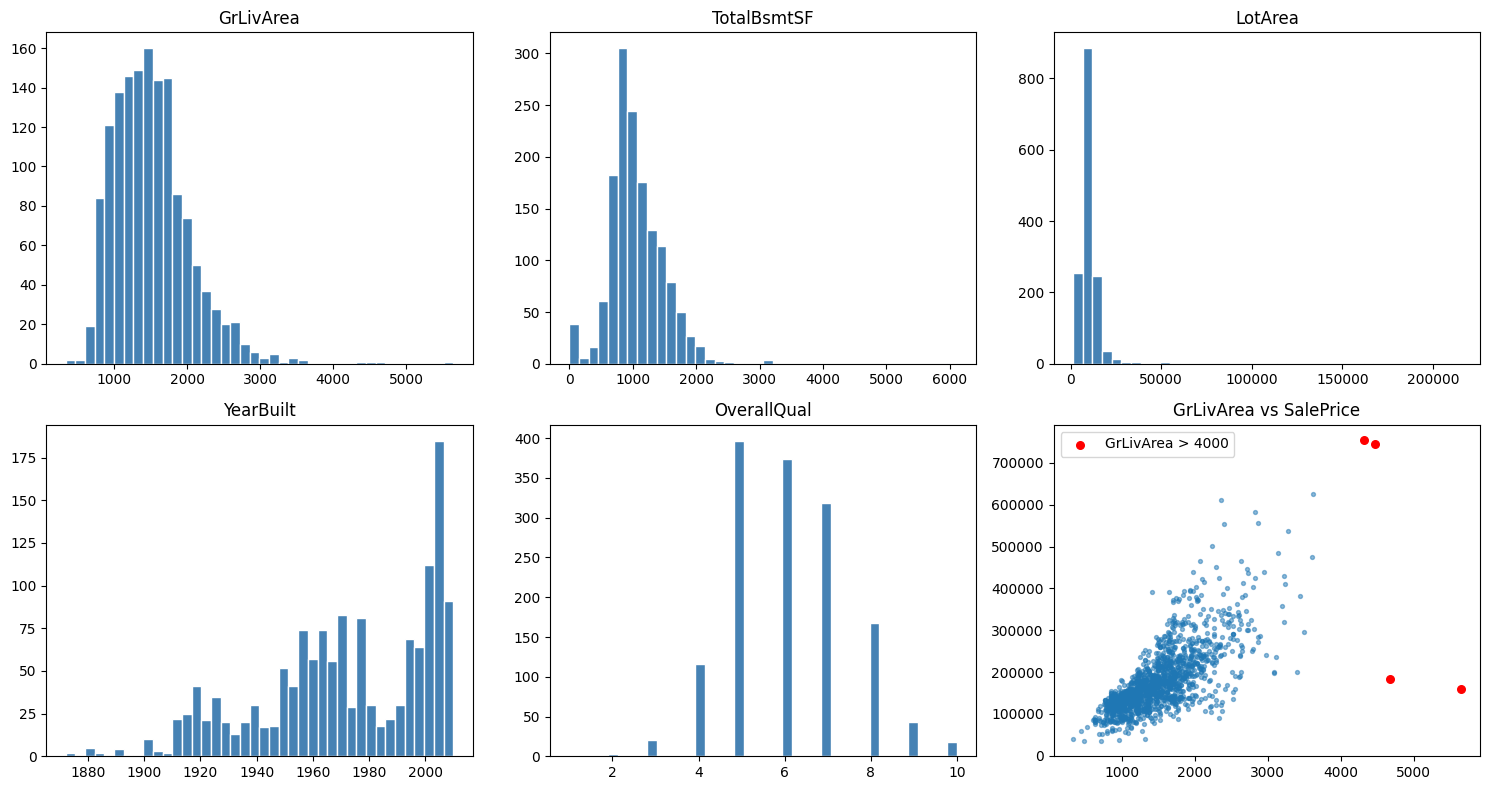

      GrLivArea SaleCondition  SalePrice
523        4676       Partial     184750
691        4316        Normal     755000
1182       4476       Abnorml     745000
1298       5642       Partial     160000


In [4]:
cols = ['GrLivArea', 'TotalBsmtSF', 'LotArea', 'YearBuilt', 'OverallQual']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, cols):
    ax.hist(df[col], bins=40, color='steelblue', edgecolor='white')
    ax.set_title(col)

# окремо: площа житла проти ціни, щоб побачити викиди
ax = axes.flat[-1]
big = df['GrLivArea'] > 4000
ax.scatter(df.loc[~big, 'GrLivArea'], df.loc[~big, 'SalePrice'], s=8, alpha=0.5)
ax.scatter(df.loc[big, 'GrLivArea'], df.loc[big, 'SalePrice'], s=30, color='red', label='GrLivArea > 4000')
ax.set_title('GrLivArea vs SalePrice')
ax.legend()
plt.tight_layout()
plt.show()

print(df.loc[big, ['GrLivArea', 'SaleCondition', 'SalePrice']])

`GrLivArea`, `TotalBsmtSF` і особливо `LotArea` скошені вправо (є поодинокі ділянки понад 100 000 кв. футів), `YearBuilt` має пік у 2000-х роках, `OverallQual` є дискретною оцінкою від 1 до 10 з більшістю будинків на рівнях 5, 6, 7.

Житлова площа і ціна мають чіткий лінійний зв'язок, але чотири будинки з `GrLivArea > 4000` випадають. Два з них (`Partial`, тобто продаж недобудованого будинку) мають найбільшу площу в датасеті, 4676 і 5642 кв. футів, а продані дешевше за 200 000 \$. Автор датасету Ames Housing (D. De Cock, 2011) прямо радить прибрати будинки з площею понад 4000 кв. футів. Правило взяте з документації, а не обчислене з даних, тому застосування його до всього датасету до розбиття не є витоком даних.

In [5]:
df = df[df['GrLivArea'] <= 4000].reset_index(drop=True)
df['LogPrice'] = np.log1p(df['SalePrice'])  # цільова змінна моделі
print('Після видалення викидів:', df.shape)

Після видалення викидів: (1456, 82)


### 1.2 Розбиття вибірки на Train / Validation / Test

Розбиваємо дані **до** відбору ознак, кодування та масштабування, щоб усі ці кроки бачили лише Train. Пропорції 70 / 15 / 15, перемішування з фіксованим seed.

In [6]:
def train_val_test_split(data, train_ratio=0.70, val_ratio=0.15, seed=SEED):
    idx = np.random.default_rng(seed).permutation(len(data))
    n_train = int(train_ratio * len(data))
    n_val = int(val_ratio * len(data))
    return (data.iloc[idx[:n_train]].copy(),
            data.iloc[idx[n_train:n_train + n_val]].copy(),
            data.iloc[idx[n_train + n_val:]].copy())

train_df, val_df, test_df = train_val_test_split(df)
print(f'Train: {len(train_df)}, Validation: {len(val_df)}, Test: {len(test_df)}')

Train: 1019, Validation: 218, Test: 219


**Питання: чому дані треба розбивати до, а не після масштабування, кодування та інших операцій, які навчаються на даних? Що таке Data Leakage?**

**Data Leakage** (витік даних) означає ситуацію, коли під час навчання модель або етап попередньої обробки отримує інформацію, якої в реальному застосуванні в неї не було б: дані з тестової чи валідаційної вибірки або саму цільову змінну.

Масштабування, кодування, заповнення пропусків і відбір ознак теж "навчаються": вони обчислюють середні, стандартні відхилення, медіани, список категорій, кореляції. Якщо зробити це на всьому датасеті, ці числа частково визначатимуться тестовими прикладами. Тоді тестова вибірка вже не є "новими даними", метрики на ній виходять оптимістичнішими, ніж буде на справжніх нових будинках, а порівняння моделей стає нечесним. Тому спочатку розбиваємо дані, потім обчислюємо всі параметри обробки лише на Train і застосовуємо їх без змін до Validation і Test.

### 1.3 Відбір ознак (лише на Train)

**Числові ознаки.** Рахуємо кореляцію Пірсона кожної числової ознаки з `LogPrice` на Train.

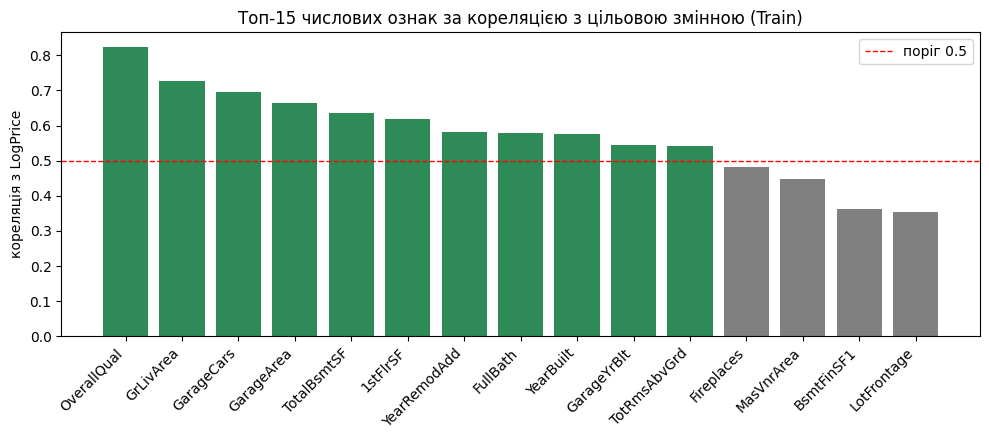

In [7]:
num_cols = train_df.select_dtypes('number').columns.drop(['Id', 'SalePrice', 'LogPrice'])
corr_target = train_df[num_cols].corrwith(train_df['LogPrice']).sort_values(key=np.abs, ascending=False)

top = corr_target.head(15)
plt.figure(figsize=(10, 4.5))
plt.bar(top.index, top.values, color=['seagreen' if abs(v) >= 0.5 else 'grey' for v in top.values])
plt.axhline(0.5, color='red', linestyle='--', linewidth=1, label='поріг 0.5')
plt.xticks(rotation=45, ha='right')
plt.ylabel('кореляція з LogPrice')
plt.title('Топ-15 числових ознак за кореляцією з цільовою змінною (Train)')
plt.legend()
plt.tight_layout()
plt.show()

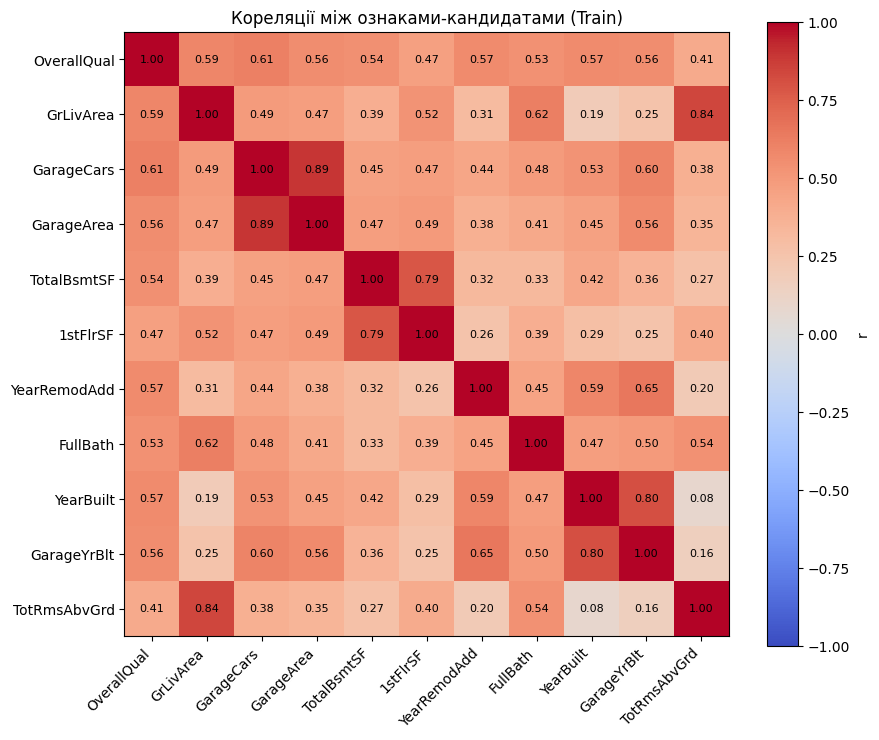

In [8]:
candidates = corr_target[corr_target.abs() >= 0.5].index.tolist()
corr_matrix = train_df[candidates].corr()

plt.figure(figsize=(9, 7.5))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label='r')
plt.xticks(range(len(candidates)), candidates, rotation=45, ha='right')
plt.yticks(range(len(candidates)), candidates)
for i in range(len(candidates)):
    for j in range(len(candidates)):
        plt.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.title('Кореляції між ознаками-кандидатами (Train)')
plt.tight_layout()
plt.show()

Правило відбору: беремо ознаки з $|r| \ge 0.5$ з цільовою змінною, починаючи з найсильнішої, і **не беремо** ознаку, якщо вона корелює з уже вибраною сильніше ніж на $0.8$ (така пара майже дублює інформацію і створює мультиколінеарність).

In [9]:
def select_features(corr_target, corr_matrix, min_target=0.5, max_mutual=0.8):
    selected = []
    for f in corr_target.index:  # ознаки вже впорядковані за |r| з ціллю
        if abs(corr_target[f]) < min_target:
            break
        twin = [s for s in selected if abs(corr_matrix.loc[f, s]) >= max_mutual]
        if twin:
            print(f'{f:13s} відкинуто: r = {corr_matrix.loc[f, twin[0]]:.2f} з {twin[0]}')
        else:
            selected.append(f)
    return selected

NUM = select_features(corr_target, corr_matrix)
print('\nОбрані числові ознаки та їхня кореляція з LogPrice:')
print(corr_target[NUM].round(3).to_string())

GarageArea    відкинуто: r = 0.89 з GarageCars
GarageYrBlt   відкинуто: r = 0.80 з YearBuilt
TotRmsAbvGrd  відкинуто: r = 0.84 з GrLivArea

Обрані числові ознаки та їхня кореляція з LogPrice:
OverallQual     0.824
GrLivArea       0.727
GarageCars      0.696
TotalBsmtSF     0.636
1stFlrSF        0.620
YearRemodAdd    0.582
FullBath        0.579
YearBuilt       0.577


**Категоріальні ознаки.** Для них кореляція Пірсона не підходить, тому рахуємо кореляційне відношення $\eta^2$ (частку дисперсії `LogPrice`, яку пояснюють середні значення по категоріях), теж лише на Train:

$$\eta^2 = \frac{\sum_k n_k(\bar y_k - \bar y)^2}{\sum_i (y_i - \bar y)^2}$$

In [10]:
def eta_squared(cat, y):
    groups = y.groupby(cat)
    return (groups.count() * (groups.mean() - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()

cat_candidates = ['Neighborhood', 'ExterQual', 'KitchenQual', 'MSZoning', 'CentralAir', 'HouseStyle', 'BldgType']
pd.DataFrame({
    'категорій': [train_df[c].nunique() for c in cat_candidates],
    'eta^2': [round(eta_squared(train_df[c], train_df['LogPrice']), 3) for c in cat_candidates],
}, index=cat_candidates).sort_values('eta^2', ascending=False)

,категорій,eta^2
Neighborhood,25,0.581
ExterQual,4,0.474
KitchenQual,4,0.453
MSZoning,5,0.193
CentralAir,2,0.116
HouseStyle,8,0.106
BldgType,5,0.049


**Обрані ознаки і чому саме вони** (усі числа пораховано на Train):

| Ознака | Тип | Обґрунтування |
|---|---|---|
| `OverallQual` | числова (оцінка 1..10) | найсильніший зв'язок з ціною, $r = 0.82$ |
| `GrLivArea` | числова | житлова площа, $r = 0.73$; `TotRmsAbvGrd` (кількість кімнат) відкинуто, бо $r = 0.84$ з площею |
| `GarageCars` | числова | місткість гаража, $r = 0.70$; `GarageArea` відкинуто, бо $r = 0.89$ з `GarageCars` |
| `TotalBsmtSF`, `1stFlrSF` | числові | площа підвалу і першого поверху, $r = 0.64$ і $0.62$; між собою $r = 0.79$, тобто трохи нижче порогу |
| `YearRemodAdd`, `YearBuilt` | числові | рік ремонту і будівництва, $r \approx 0.58$; `GarageYrBlt` відкинуто, бо $r = 0.80$ з `YearBuilt` (і в ній є пропуски) |
| `FullBath` | числова | кількість повних ванних кімнат, $r = 0.58$ |
| `KitchenQual` | порядкова категорія | $\eta^2 = 0.45$, середня log-ціна монотонно росте від `Fa` до `Ex` |
| `Neighborhood` | номінальна категорія | найбільше $\eta^2 = 0.58$: розташування сильно впливає на ціну |

`ExterQual` має трохи більше $\eta^2$ (0.47), ніж `KitchenQual`, але обидві є оцінками якості за тією самою шкалою, корелюють між собою ($r = 0.72$) і з `OverallQual` ($r = 0.72$ і $0.66$). Беремо одну, `KitchenQual`, щоб не додавати ще одну майже дубльовану ознаку. `MSZoning`, `CentralAir`, `HouseStyle`, `BldgType` пояснюють не більше 19% дисперсії, тому їх не беремо: модель лишається простою і зрозумілою.

### 1.4 Кодування категорій

* **`KitchenQual`: Ordinal Encoding** (`Po`=1, `Fa`=2, `TA`=3, `Gd`=4, `Ex`=5). Категорії мають природний порядок якості, і ціна з ним монотонно росте, тому одне число зберігає всю інформацію без зайвих стовпців.
* **`Neighborhood`: One-Hot Encoding.** Райони не мають порядку, тому порядкові номери створили б штучну залежність ("район №20 удвічі більший за №10"). One-Hot дає кожному району власний коефіцієнт. Одну категорію (найчастішу, `NAmes`) відкидаємо як базову: інакше сума всіх dummy-стовпців дорівнює 1 і повторює стовпець для $b$ (dummy variable trap, точна мультиколінеарність). Райони, яких у Train менше 10 будинків, об'єднуємо в `Other`, бо оцінювати окремий коефіцієнт за 2..9 прикладами ненадійно.
* **Target Encoding не використовуємо.** Він замінює категорію середньою ціною в ній, тобто використовує саму цільову змінну. Без крос-валідації і згладжування це прямий шлях до витоку даних і перенавчання на рідкісних категоріях (середнє з 2 будинків дуже шумне). Для 25 районів One-Hot дає помірну кількість ознак, тож потреби в Target Encoding немає.

**Питання: як обробляти категорії, які з'являться на Validation/Test, але яких не було в Train?**

Список категорій і всі параметри кодування беремо лише з Train. Будь-який район, якого немає серед частих районів Train, потрапляє в `Other`: модель використовує для нього коефіцієнт "інших рідкісних районів", не падає з помилкою і не створює нового стовпця, якого модель не бачила. Для `KitchenQual` невідоме значення або пропуск замінюємо модою Train (`TA` = 3). Пропуски в числових ознаках заповнюємо медіаною Train. Останні рядки коду нижче перевіряють це на вигаданому районі `NewDistrict` і невідомій якості кухні `???`.

In [11]:
QUAL_MAP = {'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

# усе, що потрібно для кодування, обчислюємо лише на Train
counts = train_df['Neighborhood'].value_counts()
known = counts[counts >= 10].index                 # достатньо часті райони
REFERENCE = counts.index[0]                         # найчастіший район, базова категорія
DUMMY_CATS = sorted(c for c in known if c != REFERENCE) + ['Other']
medians = train_df[NUM].median()
kitchen_mode = train_df['KitchenQual'].map(QUAL_MAP).mode()[0]

def prepare(part):
    # перетворює DataFrame у таблицю числових ознак за правилами, взятими з Train
    X = part[NUM].fillna(medians).astype(float)
    X['KitchenQual'] = part['KitchenQual'].map(QUAL_MAP).fillna(kitchen_mode)
    nbh = part['Neighborhood'].where(part['Neighborhood'].isin(known), 'Other')
    for c in DUMMY_CATS:
        X['Nbh_' + c] = (nbh == c).astype(float)
    return X

X_train_df, X_val_df, X_test_df = prepare(train_df), prepare(val_df), prepare(test_df)
y_train, y_val, y_test = (d['LogPrice'].values for d in (train_df, val_df, test_df))
FEATURES = X_train_df.columns.tolist()

print('Базова категорія Neighborhood:', REFERENCE)
print('Рідкісні райони, що пішли в Other:', sorted(set(counts.index) - set(known)))
print('Кількість ознак після кодування:', len(FEATURES))

# перевірка: район, якого не було в Train, і невідома якість кухні
demo = pd.DataFrame([dict(train_df.iloc[0][NUM], KitchenQual='???', Neighborhood='NewDistrict')])
prepare(demo)[['KitchenQual', 'Nbh_Other']]

Базова категорія Neighborhood: NAmes
Рідкісні райони, що пішли в Other: ['Blueste', 'NPkVill', 'Veenker']
Кількість ознак після кодування: 31


,KitchenQual,Nbh_Other
0,3.0,1.0


### 1.5 Масштабування

Стандартизація $x' = \dfrac{x - \mu}{\sigma}$. Параметри $\mu$ і $\sigma$ обчислюються **лише на Train** і потім застосовуються до Validation і Test.

Стандартизуємо всі стовпці, включно з dummy-ознаками районів. Причина: у рідкісного району (10 будинків з 1019) dummy-ознака має дисперсію близько $0.01$, тобто в сотні разів меншу, ніж у числових ознак після стандартизації. Тоді функція втрат вздовж цієї ваги дуже полога, і Batch GD підбирає таку вагу сотні епох (у пробному запуску без масштабування dummy Batch GD за 200 епох дійшов лише до $R^2 \approx 0.80$ на Train). Чому так відбувається, детально показано в Експерименті А.

In [12]:
class StandardScaler:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0  # захист від ділення на нуль
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

X_train_raw, X_val_raw, X_test_raw = (d.values.astype(float) for d in (X_train_df, X_val_df, X_test_df))

scaler = StandardScaler().fit(X_train_raw)   # mu і sigma лише з Train
X_train, X_val, X_test = (scaler.transform(X) for X in (X_train_raw, X_val_raw, X_test_raw))

k = len(NUM) + 1   # числові ознаки та KitchenQual стоять першими
print('Середні на Train після масштабування:', X_train[:, :k].mean(axis=0).round(3))
print('Std на Train після масштабування:   ', X_train[:, :k].std(axis=0).round(3))
print('Середні на Validation (не рівно 0):   ', X_val[:, :k].mean(axis=0).round(3))

Середні на Train після масштабування: [ 0. -0. -0.  0.  0.  0. -0.  0. -0.]
Std на Train після масштабування:    [1. 1. 1. 1. 1. 1. 1. 1. 1.]
Середні на Validation (не рівно 0):    [-0.027  0.017  0.019  0.115  0.129 -0.096 -0.045 -0.12   0.007]


## Етап 2. Реалізація лінійної регресії засобами numpy

Модель: $\hat{y} = Xw + b$, де $X$ має розмір $m \times n$.

Функція втрат (MSE з множником $\frac{1}{2}$ для зручного градієнта):
$$J(w, b) = \frac{1}{2m}\,(\hat y - y)^T(\hat y - y)$$

Градієнти у векторній формі:
$$\frac{\partial J}{\partial w} = \frac{1}{m} X^T(\hat y - y), \qquad \frac{\partial J}{\partial b} = \frac{1}{m}\sum_{i=1}^{m}(\hat y^{(i)} - y^{(i)})$$

Оновлення параметрів з кроком $\alpha$: $\;w \leftarrow w - \alpha\,\dfrac{\partial J}{\partial w}, \quad b \leftarrow b - \alpha\,\dfrac{\partial J}{\partial b}$.

Усі три варіанти градієнтного спуску відрізняються лише тим, на якій частині даних рахується градієнт: Batch GD бере всі $m$ прикладів, SGD бере один приклад, Mini-batch GD бере $B$ прикладів. Тому в класі це один параметр `batch_size`. Цикл `for` є лише по епохах і батчах; втрати та градієнти рахуються матричними операціями без циклів.

In [13]:
class LinearRegressionGD:
    def __init__(self, method='batch', lr=0.01, batch_size=32, epochs=200, tol=None, seed=SEED):
        self.method = method          # 'batch', 'sgd' або 'minibatch'
        self.lr = lr                  # learning rate (alpha)
        self.batch_size = batch_size  # розмір батчу для mini-batch
        self.epochs = epochs          # максимальна кількість епох
        self.tol = tol                # поріг зупинки за зміною J між епохами
        self.seed = seed

    def predict(self, X):
        return X @ self.w + self.b

    def cost(self, X, y):
        err = self.predict(X) - y
        return err @ err / (2 * len(y))

    def gradients(self, X, y):
        err = self.predict(X) - y
        return X.T @ err / len(y), err.mean()

    def update(self, X, y):
        dw, db = self.gradients(X, y)
        self.w -= self.lr * dw
        self.b -= self.lr * db

    def fit(self, X, y):
        m, n = X.shape
        self.w, self.b = np.zeros(n), 0.0
        rng = np.random.default_rng(self.seed)
        B = {'batch': m, 'sgd': 1, 'minibatch': self.batch_size}[self.method]

        self.history = [self.cost(X, y)]   # J на всьому Train після кожної епохи
        with np.errstate(over='ignore', invalid='ignore'):
            for epoch in range(self.epochs):
                order = np.arange(m) if B == m else rng.permutation(m)
                for start in range(0, m, B):
                    idx = order[start:start + B]
                    self.update(X[idx], y[idx])
                self.history.append(self.cost(X, y))
                if not np.isfinite(self.history[-1]):   # розбіжність: далі немає сенсу
                    break
                if self.tol is not None and abs(self.history[-2] - self.history[-1]) < self.tol:
                    break
        self.epochs_run = len(self.history) - 1
        return self

# швидка перевірка на синтетичних даних з відомими w = [2, -3], b = 5
rng = np.random.default_rng(0)
X_demo = rng.normal(size=(500, 2))
y_demo = X_demo @ np.array([2.0, -3.0]) + 5 + rng.normal(scale=0.1, size=500)
demo_model = LinearRegressionGD('batch', lr=0.1, epochs=500).fit(X_demo, y_demo)
print('w =', demo_model.w.round(3), ' b =', round(demo_model.b, 3))

w = [ 2.004 -3.005]  b = 5.005


## Етап 3. Градієнтний спуск: три варіанти оптимізації

* **Batch GD**: одне оновлення за епоху, градієнт по всіх прикладах Train.
* **SGD**: оновлення після кожного окремого прикладу, порядок прикладів перемішується щоепохи.
* **Mini-batch GD**: оновлення після кожного батчу з $B = 32$ прикладів.

**Критерій зупинки:** максимальна кількість епох (однакова для всіх методів, щоб графіки можна було порівняти). Для Batch GD додатково зупиняємося, якщо $|J_{t-1} - J_t| < 10^{-9}$. Для SGD і Mini-batch цей критерій не застосовуємо, бо їхні втрати коливаються від епохи до епохи і мала зміна $J$ ще не означає збіжність.

**Підбір Learning Rate.** Для кожного методу перебираємо кілька значень $\alpha$ і вибираємо те, що дає найменшу MSE на **Validation** (Test при цьому не використовується).

In [14]:
EPOCHS = 200
B = 32

def mse(model, X, y):
    with np.errstate(over='ignore', invalid='ignore'):
        err = model.predict(X) - y
        return err @ err / len(y)

def fluctuation(history, last=50):
    # std різниць J між сусідніми епохами: плавна крива дає ~0, "шумна" дає великі значення
    return np.std(np.diff(history[-last:]))

lr_grid = {
    'batch':     [0.01, 0.03, 0.1, 0.3, 1.0],
    'minibatch': [0.001, 0.003, 0.01, 0.03, 0.1, 0.3],
    'sgd':       [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03],
}

rows, best_lr = [], {}
for method, grid in lr_grid.items():
    scores = {}
    for lr in grid:
        model = LinearRegressionGD(method, lr=lr, batch_size=B, epochs=EPOCHS, tol=1e-9 if method == 'batch' else None)
        model.fit(X_train, y_train)
        val = mse(model, X_val, y_val)
        diverged = not np.isfinite(model.history[-1]) or model.history[-1] > model.history[0]
        scores[lr] = np.inf if diverged else val
        rows.append({'метод': method, 'lr': lr, 'MSE Validation': 'розбіжність' if diverged else round(val, 5)})
    best_lr[method] = min(scores, key=scores.get)

print('Найкращі lr за Validation:', best_lr)

# для Batch GD крок стабільний, лише якщо alpha < 2 / lambda_max (lambda_max: найбільше власне число A^T A / m)
A = np.column_stack([np.ones(len(X_train)), X_train])
lam_max = np.linalg.eigvalsh(A.T @ A / len(X_train)).max()
print(f'Теоретична межа стабільності Batch GD: alpha < 2 / lambda_max = {2 / lam_max:.3f}')
pd.DataFrame(rows).pivot(index='lr', columns='метод', values='MSE Validation')[['batch', 'minibatch', 'sgd']].fillna('')

Найкращі lr за Validation: {'batch': 0.3, 'minibatch': 0.01, 'sgd': 0.0003}
Теоретична межа стабільності Batch GD: alpha < 2 / lambda_max = 0.365


метод,batch,minibatch,sgd
lr,,,
0.0001,,,0.02527
0.0003,,,0.02511
0.0010,,0.02563,0.02516
0.0030,,0.02529,0.02595
0.0100,2.55749,0.02512,0.02805
0.0300,0.02575,0.0252,розбіжність
0.1000,0.02529,0.02664,
0.3000,0.02512,0.02889,
1.0000,розбіжність,,


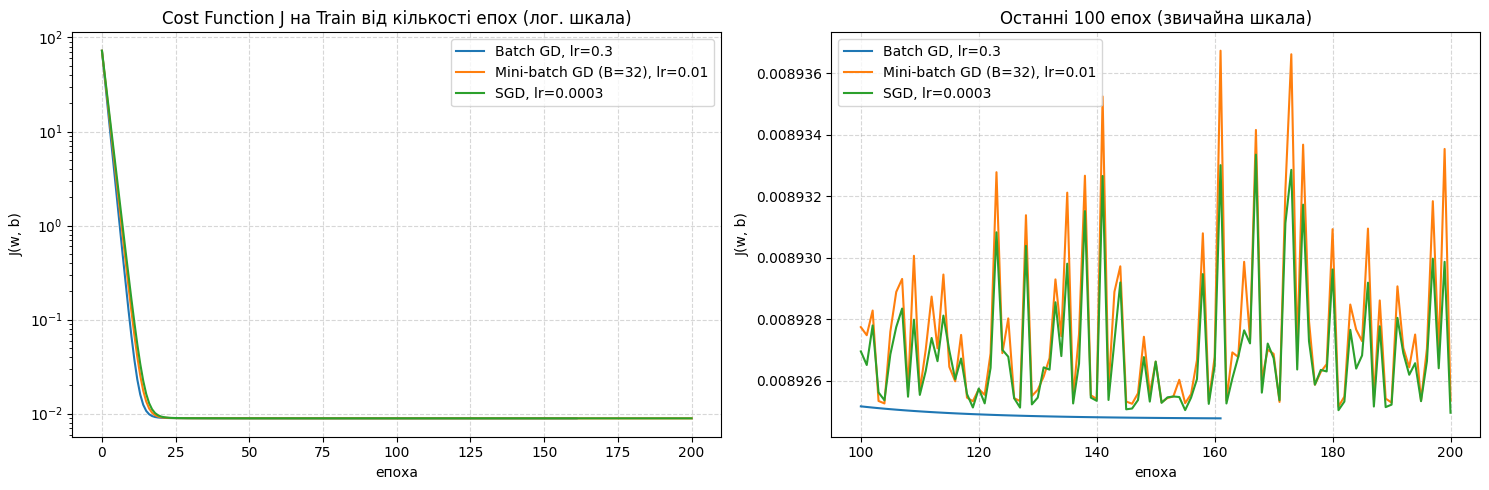

,lr,епох,оновлень за епоху,J в кінці,"коливання J (std різниць, 50 епох)","час, с"
Batch GD,0.3000,161,1,0.00892,2.8e-09,0.01
Mini-batch GD (B=32),0.0100,200,32,0.00893,4.5e-06,0.09
SGD,0.0003,200,1019,0.00892,3.2e-06,2.43


In [15]:
names = {'batch': 'Batch GD', 'minibatch': f'Mini-batch GD (B={B})', 'sgd': 'SGD'}
models, times = {}, {}
for method in ['batch', 'minibatch', 'sgd']:
    t0 = time.perf_counter()
    models[method] = LinearRegressionGD(method, lr=best_lr[method], batch_size=B, epochs=EPOCHS,
                                        tol=1e-9 if method == 'batch' else None).fit(X_train, y_train)
    times[method] = time.perf_counter() - t0

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for method, model in models.items():
    label = f'{names[method]}, lr={model.lr}'
    ax[0].plot(model.history, label=label)
    ax[1].plot(range(EPOCHS - 100, model.epochs_run + 1), model.history[EPOCHS - 100:], label=label)
ax[0].set_yscale('log')
ax[0].set_title('Cost Function J на Train від кількості епох (лог. шкала)')
ax[1].set_title('Останні 100 епох (звичайна шкала)')
for a in ax:
    a.set_xlabel('епоха')
    a.set_ylabel('J(w, b)')
    a.grid(True, linestyle='--', alpha=0.5)
    a.legend()
plt.tight_layout()
plt.show()

pd.DataFrame({
    'lr': [models[m].lr for m in models],
    'епох': [models[m].epochs_run for m in models],
    'оновлень за епоху': [1, int(np.ceil(len(y_train) / B)), len(y_train)],
    'J в кінці': [round(models[m].history[-1], 5) for m in models],
    'коливання J (std різниць, 50 епох)': [f'{fluctuation(models[m].history):.1e}' for m in models],
    'час, с': [round(times[m], 2) for m in models],
}, index=[names[m] for m in models])

**Вплив розміру батчу.** Запускаємо Mini-batch GD з однаковим $\alpha = 0.03$ і різними $B$.

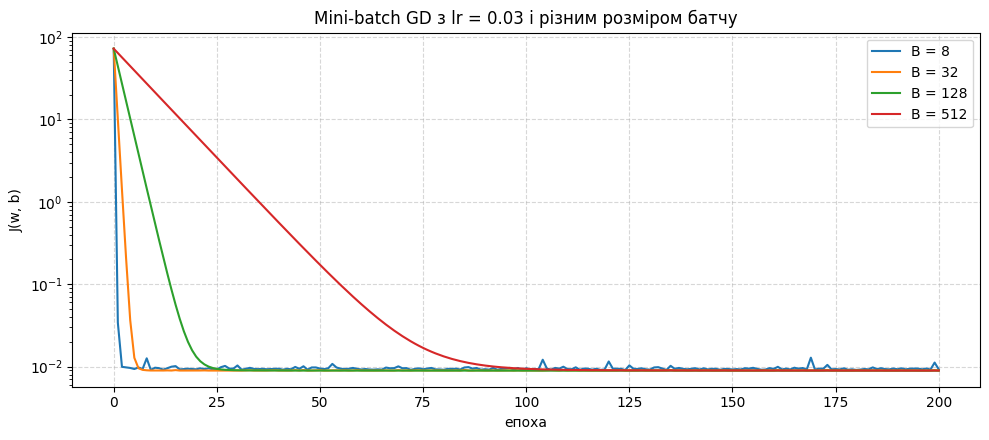

,оновлень за епоху,J після 20 епох,J після 200 епох,"коливання J (std різниць, 50 епох)","час на епоху, мс"
B,,,,,
8,128,0.00926,0.00925,9.0e-04,1.67
32,32,0.00897,0.00894,5.2e-05,0.49
128,8,0.01317,0.00892,2.4e-06,0.17
512,2,6.32100,0.00894,1.3e-07,0.09


In [16]:
batch_rows = []
plt.figure(figsize=(10, 4.5))
for b_size in [8, 32, 128, 512]:
    t0 = time.perf_counter()
    model = LinearRegressionGD('minibatch', lr=0.03, batch_size=b_size, epochs=EPOCHS).fit(X_train, y_train)
    elapsed = time.perf_counter() - t0
    plt.plot(model.history, label=f'B = {b_size}')
    batch_rows.append({'B': b_size, 'оновлень за епоху': int(np.ceil(len(y_train) / b_size)),
                       'J після 20 епох': round(model.history[20], 5), 'J після 200 епох': round(model.history[-1], 5),
                       'коливання J (std різниць, 50 епох)': f'{fluctuation(model.history):.1e}',
                       'час на епоху, мс': round(1000 * elapsed / EPOCHS, 2)})
plt.yscale('log')
plt.xlabel('епоха')
plt.ylabel('J(w, b)')
plt.title('Mini-batch GD з lr = 0.03 і різним розміром батчу')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
pd.DataFrame(batch_rows).set_index('B')

### Аналіз графіків

З підібраними $\alpha$ усі три методи доходять до того самого мінімуму $J \approx 0.0089$ приблизно за 20 епох (лівий графік). Різниця між ними видно на правому графіку і в таблицях.

**Який метод збігається найстабільніше?** Batch GD. Він рахує точний градієнт по всій вибірці, тому $J$ спадає монотонно, без жодного стрибка: розкид різниць між епохами $2.8 \cdot 10^{-9}$, і на 161 епосі спрацював критерій зупинки $|J_{t-1} - J_t| < 10^{-9}$.

**Який метод має найбільші коливання Cost Function?** Стохастичні методи, і найсильніше SGD. Його градієнт оцінено за одним будинком, тому напрямок кожного кроку дуже шумний. Через це SGD витримує лише малий крок: найкращий $\alpha = 0.0003$, при $\alpha = 0.01$ MSE на Validation вже гірша (0.0281 проти 0.0251 у Mini-batch з тим самим кроком), а при $\alpha = 0.03$ SGD розходиться, тоді як Batch GD стабільний навіть при $\alpha = 0.3$. З підібраними кроками коливання SGD і Mini-batch за епоху близькі ($3.2 \cdot 10^{-6}$ і $4.5 \cdot 10^{-6}$), бо рівень шуму приблизно пропорційний $\alpha / B$, а $0.0003 / 1 \approx 0.01 / 32$.

**Як розмір batch впливає на швидкість та стабільність?** (останній графік, однаковий $\alpha = 0.03$)
* Менший $B$ дає більше оновлень за епоху, тому потрібно менше епох: після 20 епох $B = 32$ уже має $J = 0.00897$, а $B = 512$ ще $6.32$ (лише 2 кроки за епоху).
* Але кожна епоха з малим батчем довша за часом (з $B = 8$ приблизно на порядок довша, ніж з $B = 512$), бо numpy ефективніше обробляє одну велику матрицю, ніж багато маленьких. Тому SGD ($B = 1$) працює найдовше, хоча за епохи збігається не гірше.
* Менший $B$ дає більший шум: розкид $J$ між епохами зростає з $1.3 \cdot 10^{-7}$ ($B = 512$) до $9 \cdot 10^{-4}$ ($B = 8$), і з $B = 8$ модель так і "тремтить" навколо мінімуму на рівні $J = 0.00925$ замість $0.00892$.
* $B = 32$ є компромісом: швидка збіжність за епохами, невеликий шум, векторизовані обчислення.

**Як вибір Learning Rate впливає на збіжність?** (таблиця підбору $\alpha$)
* Замалий $\alpha$ дає повільну збіжність: Batch GD з $\alpha = 0.01$ за 200 епох має MSE 2.56, тобто ще навіть не "знайшов" середню ціну ($b$ мав пройти шлях від 0 до $\approx 12$).
* Оптимальний $\alpha$ дає швидкий і стабільний спуск.
* Завеликий $\alpha$ дає перестрибування через мінімум і розбіжність. Для Batch GD теорія дає межу $\alpha < 2/\lambda_{max} = 0.365$, і справді $\alpha = 0.3$ збігається, а $\alpha = 1$ розходиться. У стохастичних методах ще до розбіжності великий $\alpha$ збільшує шум навколо мінімуму (Mini-batch з $\alpha = 0.1$ і $0.3$ має гіршу MSE на Validation: 0.0266 і 0.0289).

## Етап 4. Оцінка якості та коефіцієнт детермінації $R^2$

$$R^2 = 1 - \frac{\sum_{i=1}^m (y^{(i)} - \hat y^{(i)})^2}{\sum_{i=1}^m (y^{(i)} - \bar y)^2} = 1 - \frac{SS_{res}}{SS_{tot}}$$

In [17]:
def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

r2_table = pd.DataFrame({
    split: [round(r2_score(y, models[m].predict(X)), 4) for m in models]
    for split, (X, y) in {'R2 Train': (X_train, y_train), 'R2 Validation': (X_val, y_val), 'R2 Test': (X_test, y_test)}.items()
}, index=[names[m] for m in models])
r2_table['RMSE Test (log)'] = [round(np.sqrt(mse(models[m], X_test, y_test)), 4) for m in models]
r2_table

,R2 Train,R2 Validation,R2 Test,RMSE Test (log)
Batch GD,0.8873,0.8483,0.8563,0.1418
Mini-batch GD (B=32),0.8873,0.8483,0.8564,0.1417
SGD,0.8873,0.8483,0.8563,0.1418


In [18]:
# коли R^2 буває від'ємним
untrained = LinearRegressionGD('batch', lr=0.1, epochs=0).fit(X_train, y_train)   # w = 0, b = 0
short = LinearRegressionGD('batch', lr=0.01, epochs=20).fit(X_train, y_train)      # недонавчена модель
print(f"Модель до навчання (y_hat = 0):        R2 Test = {r2_score(y_test, untrained.predict(X_test)):.1f}")
print(f"Batch GD, lr = 0.01, лише 20 епох:     R2 Test = {r2_score(y_test, short.predict(X_test)):.2f}")
print(f"Константа = середнє y з Train:         R2 Test = {r2_score(y_test, np.full_like(y_test, y_train.mean())):.4f}")

Модель до навчання (y_hat = 0):        R2 Test = -1036.3
Batch GD, lr = 0.01, лише 20 епох:     R2 Test = -693.43
Константа = середнє y з Train:         R2 Test = -0.0030


**Статистичний зміст $R^2$.** $SS_{tot}$ показує, наскільки ціни розкидані навколо середнього, тобто похибку найпростішої "моделі", яка завжди прогнозує середнє. $SS_{res}$ показує похибку нашої моделі. Отже, $R^2$ дорівнює частці дисперсії цільової змінної, яку пояснює модель. $R^2 = 0.856$ на Test означає, що модель пояснює близько 86% відмінностей у log-ціні між будинками, а решта 14% припадає на фактори, яких немає в моделі, і випадковий шум. Для лінійної регресії з вільним членом на навчальних даних $R^2$ також дорівнює квадрату кореляції між $y$ і $\hat y$.

**Чи може $R^2$ бути від'ємним?** Так, коли модель прогнозує гірше за константу, що дорівнює середньому цієї вибірки ($SS_{res} > SS_{tot}$). Для оптимальної за MSE лінійної моделі з $b$ на Train це неможливо, бо константа є її окремим випадком. Але від'ємний $R^2$ буває на нових даних або в недонавченої моделі: модель до навчання ($\hat y = 0$) має $R^2 = -1036$, Batch GD з $\alpha = 0.01$ після 20 епох має $R^2 = -693$, бо $b$ ще далеко від середньої log-ціни $\approx 12$. Навіть константа, рівна середньому з Train, дає на Test $R^2 = -0.003$, бо середнє Test трохи інше. Також $R^2 < 0$ буває при сильному перенавчанні або коли розподіл нових даних відрізняється від навчальних.

**Train проти Test.** $R^2$ становить 0.887 на Train, 0.848 на Validation і 0.856 на Test. Розрив між Train і Test лише близько 0.03, тобто модель майже однаково працює на бачених і нових даних: **перенавчання немає**. При цьому $R^2 \approx 0.86$ досить високий, тож сильного недонавчання теж немає. Невелика залишкова похибка пояснюється тим, що лінійна модель з 31 ознакою не враховує всіх факторів ціни (стан будинку, умови продажу тощо).

**Порівняння трьох варіантів GD.** Усі три методи дали однакові $R^2$ з точністю до 0.0001, і вони збігаються з точним розв'язком Normal Equation (див. бонус). Тобто на якість фінальної моделі вибір методу тут не вплинув, бо задача опукла і кожен метод з правильним $\alpha$ доходить до того самого мінімуму. Різниця в іншому: Batch GD дає найгладшу траєкторію і найшвидший на такому невеликому датасеті, SGD найшумніший і найповільніший за часом, Mini-batch поєднує швидку збіжність за епохами з помірним шумом і найкраще масштабується на великі дані, які не вміщаються в пам'ять одним шматком.

## Етап 5. Перевірка статистичних припущень

Аналізуємо залишки $\varepsilon = y - \hat y$ найкращої за Validation моделі на навчальній вибірці (саме на ній оцінено параметри, і точок там найбільше).

Аналізуємо модель: SGD


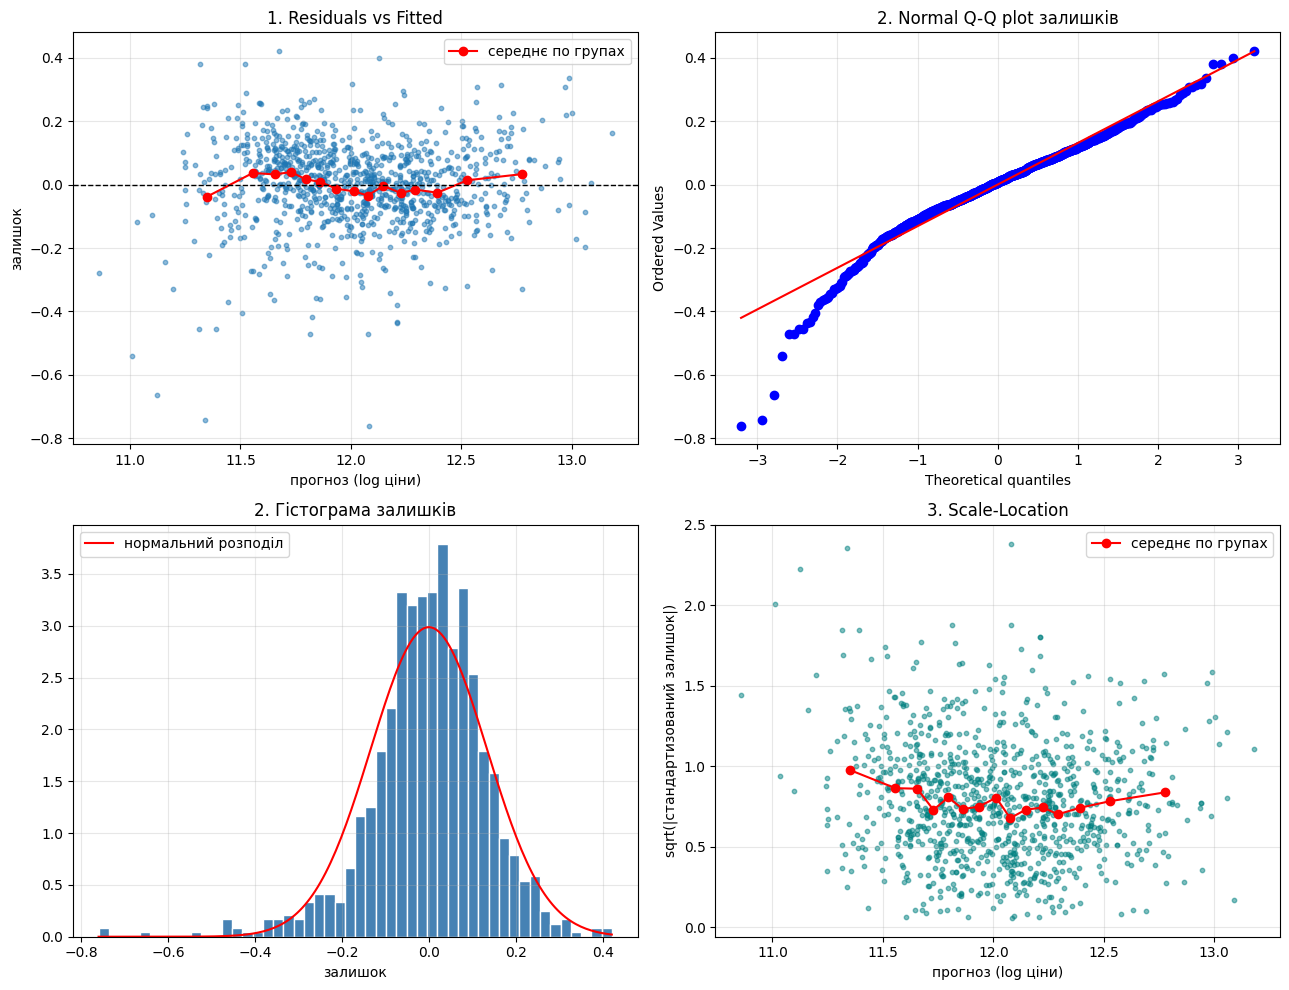

In [19]:
best = max(models, key=lambda m: r2_score(y_val, models[m].predict(X_val)))
model = models[best]
print('Аналізуємо модель:', names[best])

fitted = model.predict(X_train)
resid = y_train - fitted
std_resid = resid / resid.std()

def binned_mean(x, y, bins=15):
    # середнє y у групах за x: замінює згладжувальну лінію на графіках залишків
    order = np.argsort(x)
    parts = np.array_split(order, bins)
    return [x[p].mean() for p in parts], [y[p].mean() for p in parts]

fig, ax = plt.subplots(2, 2, figsize=(13, 10))

ax[0, 0].scatter(fitted, resid, s=10, alpha=0.5)
ax[0, 0].plot(*binned_mean(fitted, resid), color='red', marker='o', label='середнє по групах')
ax[0, 0].axhline(0, color='black', linestyle='--', linewidth=1)
ax[0, 0].set(title='1. Residuals vs Fitted', xlabel='прогноз (log ціни)', ylabel='залишок')
ax[0, 0].legend()

stats.probplot(resid, dist='norm', plot=ax[0, 1])
ax[0, 1].set_title('2. Normal Q-Q plot залишків')

ax[1, 0].hist(resid, bins=50, density=True, color='steelblue', edgecolor='white')
grid = np.linspace(resid.min(), resid.max(), 200)
ax[1, 0].plot(grid, stats.norm.pdf(grid, resid.mean(), resid.std()), color='red', label='нормальний розподіл')
ax[1, 0].set(title='2. Гістограма залишків', xlabel='залишок')
ax[1, 0].legend()

sl = np.sqrt(np.abs(std_resid))
ax[1, 1].scatter(fitted, sl, s=10, alpha=0.5, color='teal')
ax[1, 1].plot(*binned_mean(fitted, sl), color='red', marker='o', label='середнє по групах')
ax[1, 1].set(title='3. Scale-Location', xlabel='прогноз (log ціни)', ylabel='sqrt(|стандартизований залишок|)')
ax[1, 1].legend()

for a in ax.flat:
    a.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
sw_stat, sw_p = stats.shapiro(resid)
print(f'Тест Шапіро-Уїлка: W = {sw_stat:.4f}, p-value = {sw_p:.2e}')
print(f'Асиметрія залишків: {stats.skew(resid):.2f}, ексцес: {stats.kurtosis(resid):.2f}')
print(f'Частка залишків у межах ±2 std: {np.mean(np.abs(std_resid) < 2):.3f} (для нормального розподілу 0.954)')

rho, p_rho = stats.spearmanr(fitted, np.abs(resid))
print(f'Кореляція Спірмена між прогнозом і |залишком|: rho = {rho:.3f}, p-value = {p_rho:.3f}')

thirds = np.array_split(np.argsort(fitted), 3)
print('Std залишків у третинах за прогнозом (дешеві, середні, дорогі):',
      [round(float(resid[t].std()), 4) for t in thirds])

Тест Шапіро-Уїлка: W = 0.9598, p-value = 4.01e-16
Асиметрія залишків: -0.84, ексцес: 3.14
Частка залишків у межах ±2 std: 0.950 (для нормального розподілу 0.954)
Кореляція Спірмена між прогнозом і |залишком|: rho = -0.091, p-value = 0.004
Std залишків у третинах за прогнозом (дешеві, середні, дорогі): [0.1539, 0.1234, 0.1189]


**Мультиколінеарність.** $VIF_j = \dfrac{1}{1 - R_j^2}$, де $R_j^2$ показує, наскільки ознаку $j$ можна передбачити іншими ознаками. Еквівалентно, $VIF_j$ дорівнює $j$-му діагональному елементу оберненої кореляційної матриці ознак. Орієнтири: $VIF < 5$ нормально, $5 \ldots 10$ помірна, $> 10$ сильна мультиколінеарність.

In [21]:
def vif(X):
    return np.diag(np.linalg.inv(np.corrcoef(X, rowvar=False)))

vif_model = pd.Series(vif(X_train), index=FEATURES).sort_values(ascending=False)
print('VIF ознак моделі (топ-10):')
print(vif_model.head(10).round(2).to_string())

# для порівняння: якби взяли всі кандидати з |r| >= 0.5 без відкидання корельованих пар
X_cand = train_df[candidates].fillna(train_df[candidates].median()).values
print('\nVIF усіх кандидатів без відбору:')
print(pd.Series(vif(X_cand), index=candidates).sort_values(ascending=False).round(2).to_string())

VIF ознак моделі (топ-10):
YearBuilt      6.21
1stFlrSF       3.66
OverallQual    3.51
TotalBsmtSF    3.36
GrLivArea      3.13
Nbh_CollgCr    2.62
Nbh_NridgHt    2.43
KitchenQual    2.40
FullBath       2.36
Nbh_Somerst    2.31

VIF усіх кандидатів без відбору:
GarageCars      6.06
GarageArea      5.50
GrLivArea       5.31
TotRmsAbvGrd    3.56
1stFlrSF        3.26
TotalBsmtSF     3.23
YearBuilt       3.17
OverallQual     2.86
GarageYrBlt     2.78
FullBath        2.23
YearRemodAdd    1.93


In [22]:
# стабільність коефіцієнтів: ваги стандартизованих ознак у трьох моделей
weights = pd.DataFrame({names[m]: models[m].w[:k] for m in models}, index=FEATURES[:k]).round(4)
weights['VIF'] = vif_model[FEATURES[:k]].round(2)
weights

,Batch GD,Mini-batch GD (B=32),SGD,VIF
OverallQual,0.1044,0.1041,0.1042,3.51
GrLivArea,0.1393,0.1393,0.1393,3.13
GarageCars,0.0471,0.0472,0.0472,2.10
TotalBsmtSF,0.0530,0.0528,0.0529,3.36
1stFlrSF,0.0118,0.0118,0.0117,3.66
YearRemodAdd,0.0411,0.0409,0.0409,2.20
FullBath,-0.0243,-0.0243,-0.0243,2.36
YearBuilt,0.0393,0.0395,0.0395,6.21
KitchenQual,0.0370,0.0367,0.0370,2.40


### Висновки щодо припущень

**1. Лінійність.** Припущення лінійності в цілому виконується, тому що на графіку Residuals vs Fitted точки розкидані навколо нуля без вираженої кривої, а середні залишки по групах лежать у межах приблизно $\pm 0.04$ log-одиниці (близько 4% ціни). Є лише слабка хвиля: для найдешевших прогнозів модель трохи завищує ціну, а для найдорожчих трохи занижує. Це означає, що лінійна модель правильно описує основну залежність, а залишкова нелінійність невелика (її можна було б зменшити, додавши, наприклад, квадрат `OverallQual`).

**2. Нормальність залишків.** Припущення нормальності порушується, тому що тест Шапіро-Уїлка відхиляє нормальність ($W = 0.960$, $p \approx 4 \cdot 10^{-16}$), залишки мають від'ємну асиметрію ($-0.84$) і важкі хвости (ексцес 3.14), а на Q-Q plot ліві точки помітно нижче прямої. Тобто є кілька будинків, проданих значно дешевше, ніж прогнозує модель (продаж у поганому стані, неринкові угоди). Центральна частина розподілу добре лягає на пряму: у межах $\pm 2\sigma$ лежить 95.0% залишків проти 95.4% для нормального розподілу. Це означає, що прогнози і самі коефіцієнти залишаються коректними (метод найменших квадратів не потребує нормальності для незміщеності), але довірчі інтервали і p-value, побудовані з припущенням нормальності, були б неточними. Варто також пам'ятати, що на 1019 точках тест Шапіро-Уїлка реагує навіть на невеликі відхилення.

**3. Гомоскедастичність.** Припущення гомоскедастичності слабко порушується, тому що на графіку Scale-Location середня лінія спадає зліва направо, стандартне відхилення залишків для дешевої, середньої і дорогої третини будинків становить 0.154, 0.123 і 0.119, а кореляція Спірмена між прогнозом і $|\varepsilon|$ мала, але статистично значуща ($\rho = -0.09$, $p = 0.004$). Це означає, що ціну дешевих будинків модель прогнозує з більшою відносною похибкою, ніж дорогих. Ефект слабкий, бо логарифмування цілі вже вирівняло дисперсію (на звичайній шкалі цін розкид зростав би разом із ціною набагато сильніше).

**4. Відсутність мультиколінеарності.** Припущення виконується, тому що всі VIF менші за 10, а найбільший $VIF = 6.21$ у `YearBuilt` (помірна мультиколінеарність, решта ознак не вище 3.66). `YearBuilt` частково пояснюють dummy-ознаки районів і рік ремонту: райони забудовувались у певні роки, тому серед лише числових кандидатів її VIF був 3.17. Відбір ознак на Етапі 1 спрацював: без нього `GarageCars`, `GarageArea` і `GrLivArea` мали б VIF понад 5. Це означає, що коефіцієнти моделі оцінено стійко.

**Чи вплинула мультиколінеарність на коефіцієнти?** На стабільність не вплинула: три різні алгоритми, що стартують однаково, але йдуть різними шляхами, дали майже однакові ваги (наприклад, для `YearBuilt` від 0.0393 до 0.0395), і вони відрізняються від точного розв'язку не більше ніж на 0.0004. А от інтерпретацію корельовані ознаки ускладнюють. `FullBath` має від'ємну вагу ($-0.024$), хоча сама по собі корелює з ціною додатно ($r = 0.58$): вага показує ефект **при фіксованих інших ознаках**, тобто додаткова ванна при тій самій житловій площі ($r = 0.62$ між ними) означає менше місця на інші кімнати. Так само `1stFlrSF` має малу вагу 0.012, бо більшу частину її інформації вже несе `TotalBsmtSF` ($r = 0.79$). Тому окремі коефіцієнти корельованих ознак не можна читати як "чистий" вплив ознаки на ціну.

Оскільки суттєвої мультиколінеарності немає ($VIF < 10$), Експеримент В з Ridge-регресією не потрібен. На Етапі 6 виконуємо Експеримент А.

## Етап 6. Експеримент А: вплив масштабування

Запускаємо Mini-batch GD ($B = 32$) на тих самих ознаках, але **без стандартизації** (`X_train_raw`), і порівнюємо зі стандартизованими даними. Learning Rate для кожного варіанта підбираємо за Validation.

In [23]:
raw_grid = [1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
raw_rows, raw_scores = [], {}
for lr in raw_grid:
    m_raw = LinearRegressionGD('minibatch', lr=lr, batch_size=B, epochs=EPOCHS).fit(X_train_raw, y_train)
    val = mse(m_raw, X_val_raw, y_val)
    raw_scores[lr] = val if np.isfinite(val) else np.inf
    raw_rows.append({'lr': lr, 'епох до зупинки': m_raw.epochs_run,
                     'MSE Validation': 'розбіжність' if not np.isfinite(val) else f'{val:.4g}'})
best_raw_lr = min(raw_scores, key=raw_scores.get)
print('Найкращий lr без масштабування:', best_raw_lr, '| зі стандартизацією:', best_lr['minibatch'])
pd.DataFrame(raw_rows).set_index('lr')

Найкращий lr без масштабування: 1e-08 | зі стандартизацією: 0.01


,епох до зупинки,MSE Validation
lr,,
1.000000e-09,200,0.09359
1.000000e-08,200,0.03453
1.000000e-07,200,0.0348
1.000000e-06,5,розбіжність
1.000000e-05,3,розбіжність


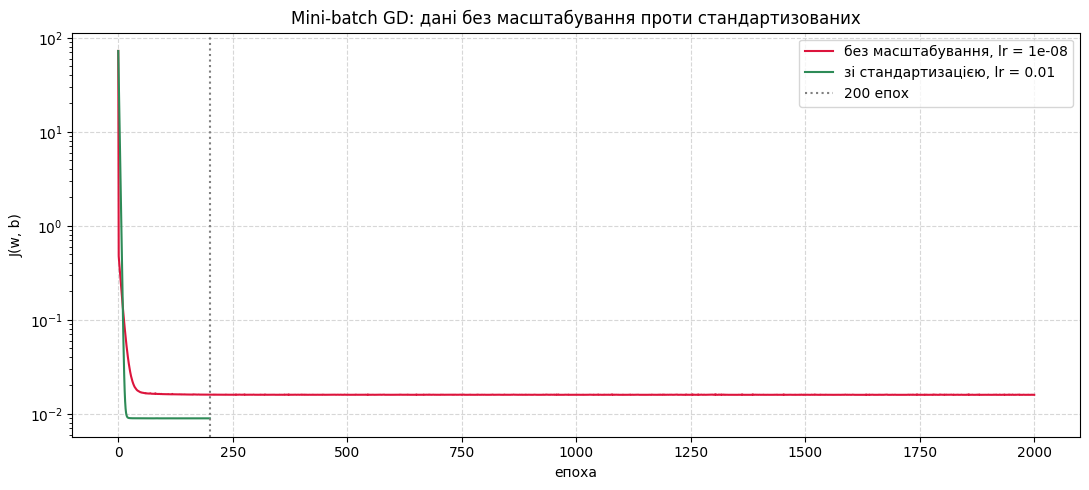

,lr,епох,J в кінці,епох до J <= 1.05 J*,R2 Validation,число обумовленості
без масштабування,1.000000e-08,200,0.01598,не досягнуто,0.7914,4.83e+11
без масштабування,1.000000e-08,2000,0.01588,не досягнуто,0.7984,4.83e+11
стандартизовані,1.000000e-02,200,0.00893,19,0.8483,6.71e+01


In [24]:
model_raw = LinearRegressionGD('minibatch', lr=best_raw_lr, batch_size=B, epochs=EPOCHS).fit(X_train_raw, y_train)
model_raw_long = LinearRegressionGD('minibatch', lr=best_raw_lr, batch_size=B, epochs=2000).fit(X_train_raw, y_train)
model_std = models['minibatch']

plt.figure(figsize=(11, 5))
plt.plot(model_raw_long.history, label=f'без масштабування, lr = {best_raw_lr}', color='crimson')
plt.plot(model_std.history, label=f'зі стандартизацією, lr = {model_std.lr}', color='seagreen')
plt.axvline(EPOCHS, color='grey', linestyle=':', label=f'{EPOCHS} епох')
plt.yscale('log')
plt.xlabel('епоха')
plt.ylabel('J(w, b)')
plt.title('Mini-batch GD: дані без масштабування проти стандартизованих')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

def condition_number(X, bias=True):
    A = np.column_stack([np.ones(len(X)), X]) if bias else X   # стовпець одиниць для b
    eig = np.linalg.eigvalsh(A.T @ A / len(X))
    return eig.max() / eig.min()

def epochs_to(history, level):
    hit = np.nonzero(np.array(history) <= level)[0]
    return int(hit[0]) if len(hit) else None

target = 1.05 * model_std.history[-1]   # J в межах 5% від фінального значення стандартизованої моделі
pd.DataFrame({
    'lr': [model_raw.lr, model_raw_long.lr, model_std.lr],
    'епох': [EPOCHS, 2000, EPOCHS],
    'J в кінці': [round(model_raw.history[-1], 5), round(model_raw_long.history[-1], 5), round(model_std.history[-1], 5)],
    'епох до J <= 1.05 J*': [epochs_to(h.history, target) or 'не досягнуто' for h in (model_raw, model_raw_long, model_std)],
    'R2 Validation': [round(r2_score(y_val, mm.predict(X_v)), 4) for mm, X_v in
                      ((model_raw, X_val_raw), (model_raw_long, X_val_raw), (model_std, X_val))],
    'число обумовленості': [f'{condition_number(X_train_raw):.2e}'] * 2 + [f'{condition_number(X_train):.2e}'],
}, index=['без масштабування', 'без масштабування', 'стандартизовані'])

Щоб побачити геометрію, візьмемо дві ознаки з різним масштабом, `GrLivArea` (сотні квадратних футів) і `YearBuilt` (десятки років), і намалюємо лінії рівня функції втрат $J(w_1, w_2)$ (дані центровані, тому $b$ не потрібен) разом із траєкторією Batch GD з однаковою кількістю кроків. В обох випадках $\alpha = 1/\lambda_{max}$, тобто найбільший "безпечний" крок для цих даних. Масштаб осей однаковий, щоб форма еліпсів не спотворювалась.

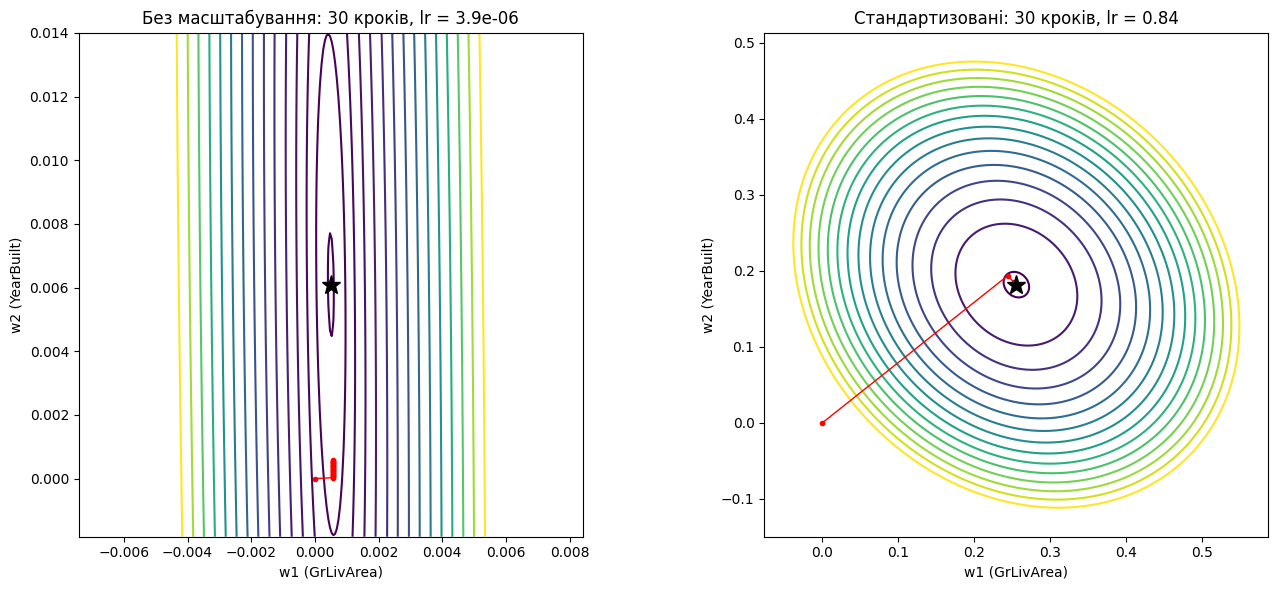

Число обумовленості для двох ознак: без масштабування 301.1, після стандартизації 1.5


In [25]:
def gd_path(X, y, lr, steps):
    w, path = np.zeros(2), [np.zeros(2)]
    for _ in range(steps):
        w = w - lr * X.T @ (X @ w - y) / len(y)
        path.append(w.copy())
    return np.array(path)

def plot_contours(ax, X, y, path, title):
    w_opt = np.linalg.lstsq(X, y, rcond=None)[0]   # лише щоб знайти центр рисунка
    span = np.abs(w_opt).max() * 1.3
    w1, w2 = np.meshgrid(np.linspace(-span, span, 300) + w_opt[0], np.linspace(-span, span, 300) + w_opt[1])
    W = np.stack([w1.ravel(), w2.ravel()])
    err = X @ W - y[:, None]
    J = (err ** 2).mean(axis=0).reshape(w1.shape) / 2
    ax.contour(w1, w2, J, levels=np.quantile(J, np.linspace(0.002, 0.6, 15)), cmap='viridis')
    ax.plot(path[:, 0], path[:, 1], 'o-', color='red', markersize=3, linewidth=1)
    ax.plot(*w_opt, '*', color='black', markersize=14)
    ax.set_title(title)
    ax.set_xlabel('w1 (GrLivArea)')
    ax.set_ylabel('w2 (YearBuilt)')
    ax.set_aspect('equal')

two = [NUM.index('GrLivArea'), NUM.index('YearBuilt')]
y_c = y_train - y_train.mean()
X2_raw = X_train_raw[:, two] - X_train_raw[:, two].mean(axis=0)
X2_std = X2_raw / X2_raw.std(axis=0)

lr_raw2 = 1 / np.linalg.eigvalsh(X2_raw.T @ X2_raw / len(y_c)).max()
lr_std2 = 1 / np.linalg.eigvalsh(X2_std.T @ X2_std / len(y_c)).max()

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
plot_contours(ax[0], X2_raw, y_c, gd_path(X2_raw, y_c, lr_raw2, 30), f'Без масштабування: 30 кроків, lr = {lr_raw2:.1e}')
plot_contours(ax[1], X2_std, y_c, gd_path(X2_std, y_c, lr_std2, 30), f'Стандартизовані: 30 кроків, lr = {lr_std2:.2f}')
plt.tight_layout()
plt.show()
print(f'Число обумовленості для двох ознак: без масштабування {condition_number(X2_raw, bias=False):.1f}, '
      f'після стандартизації {condition_number(X2_std, bias=False):.1f}')

### Висновки експерименту А

**Підбір $\alpha$.** Без масштабування ознаки відрізняються масштабом на порядки: `YearBuilt` близько 2000, `GrLivArea` близько 1500, `OverallQual` від 1 до 10, dummy-ознаки 0 або 1. Mini-batch GD розходиться вже при $\alpha = 10^{-6}$ (за 5 епох), а найкращий за Validation крок $\alpha = 10^{-8}$. Зі стандартизацією найкращий крок $\alpha = 0.01$, і метод стабільний навіть при $\alpha = 0.3$, тобто допустимий крок більший приблизно в мільйон разів.

**Швидкість збіжності.** Зі стандартизацією $J$ опускається до рівня в межах 5% від мінімуму за 19 епох. Без масштабування $J$ швидко падає до $\approx 0.016$ і далі стоїть на "плато": навіть за 2000 епох $J = 0.0159$ (майже вдвічі більше за мінімум $0.0089$), а $R^2$ на Validation лише 0.798 проти 0.848.

**Геометричне пояснення.** Функція втрат лінійної регресії є квадратичною "чашею", її лінії рівня є еліпсами (еліпсоїдами), півосі яких обернено пропорційні $\sqrt{\lambda_i}$, де $\lambda_i$ власні числа матриці $\frac{1}{m}A^TA$. Відношення $\lambda_{max}/\lambda_{min}$ (число обумовленості) показує, наскільки витягнута чаша.
* Без масштабування число обумовленості $4.8 \cdot 10^{11}$: чаша перетворюється на дуже довгий і вузький яр. Головна причина в тому, що `YearBuilt` (близько 2000) майже пропорційна стовпцю одиниць для $b$, тому напрямок "збільшити $b$ і зменшити вагу `YearBuilt`" майже не змінює втрати.
* Градієнт завжди перпендикулярний до ліній рівня, тобто у вузькому яру він направлений поперек яру, на його стінку, а не вздовж до мінімуму.
* Крок обмежений найкрутішим напрямком ($\alpha < 2/\lambda_{max}$), інакше точка перестрибує з однієї стінки на іншу і розходиться (так сталося при $\alpha = 10^{-6}$). З таким крихітним кроком рух уздовж пологого дна пропорційний $\alpha \lambda_{min}$, тобто практично нульовий. Звідси плато на графіку.
* На рисунку з двома ознаками це видно напряму: без масштабування (число обумовленості 301) перший крок опускає точку на дно яру, а за наступні 30 кроків вона ледве зсувається вздовж $w_2$. Після стандартизації еліпси майже круглі (число обумовленості 1.5), градієнт показує прямо на мінімум, і GD доходить до нього за кілька кроків.

Для всієї моделі стандартизація зменшує число обумовленості з $4.8 \cdot 10^{11}$ до 67. Чаша стає майже круглою, можна брати великий крок, і модель збігається за десятки епох замість тисяч.

## Бонус. Normal Equation: виведення та обмеження

Додамо до $X$ стовпець одиниць, щоб врахувати $b$: $A = [\mathbf{1}\;X]$, $\theta = (b, w)$. Тоді

$$J(\theta) = \frac{1}{2m}(A\theta - y)^T(A\theta - y) = \frac{1}{2m}\left(\theta^T A^T A\,\theta - 2\,\theta^T A^T y + y^T y\right).$$

Функція опукла (матриця $A^TA$ додатно напіввизначена), тому мінімум там, де градієнт дорівнює нулю:

$$\nabla_\theta J = \frac{1}{m}\left(A^TA\,\theta - A^Ty\right) = 0 \;\Rightarrow\; A^TA\,\theta = A^Ty \;\Rightarrow\; \theta^* = (A^TA)^{-1}A^Ty.$$

**Обмеження:**
1. Обчислювальна складність. Побудова $A^TA$ коштує $O(mn^2)$, обернення $O(n^3)$, пам'ять $O(n^2)$. При сотнях тисяч ознак (наприклад, після One-Hot кодування тексту) це непрактично, а градієнтний спуск робить кроки за $O(mn)$.
2. $A^TA$ має бути оборотною. При точній мультиколінеарності (dummy trap, коли не відкинуто базову категорію, дублікати ознак) або коли ознак більше, ніж прикладів ($n > m$), матриця вироджена і розв'язку не існує або він не єдиний.
3. Чисельна нестійкість. Число обумовленості $A^TA$ дорівнює квадрату числа обумовленості $A$, тому при сильній кореляції ознак або різних масштабах похибки округлення сильно зростають. На практиці замість явного обернення використовують QR чи SVD розклад (`lstsq`).
4. Формула працює лише для MSE і лінійної моделі. Для логістичної регресії, нейромереж, L1 регуляризації замкненого розв'язку немає, а градієнтні методи працюють. Також не можна донавчати модель на нових даних частинами (online learning) без повного перерахунку.

Перевіримо, що градієнтний спуск дійшов майже до того самого мінімуму (Normal Equation тут лише для контролю, моделі вище навчено тільки градієнтними методами):

In [26]:
A = np.column_stack([np.ones(len(X_train)), X_train])
theta = np.linalg.solve(A.T @ A, A.T @ y_train)
b_ne, w_ne = theta[0], theta[1:]

pred_ne = lambda X: X @ w_ne + b_ne
print(f'Normal Equation: R2 Train = {r2_score(y_train, pred_ne(X_train)):.4f}, '
      f'R2 Validation = {r2_score(y_val, pred_ne(X_val)):.4f}, R2 Test = {r2_score(y_test, pred_ne(X_test)):.4f}')
for m in models:
    print(f'{names[m]:22s} max|w - w*| = {np.abs(models[m].w - w_ne).max():.4f}, '
          f'J - J* = {models[m].history[-1] - np.sum((pred_ne(X_train) - y_train) ** 2) / (2 * len(y_train)):.2e}')
print(f'Число обумовленості A^T A: стандартизовані {condition_number(X_train):.1e}, без масштабування {condition_number(X_train_raw):.1e}')

Normal Equation: R2 Train = 0.8873, R2 Validation = 0.8484, R2 Test = 0.8563
Batch GD               max|w - w*| = 0.0004, J - J* = 1.91e-08
Mini-batch GD (B=32)   max|w - w*| = 0.0003, J - J* = 6.00e-07
SGD                    max|w - w*| = 0.0002, J - J* = 2.01e-07
Число обумовленості A^T A: стандартизовані 6.7e+01, без масштабування 4.8e+11


## Загальні висновки

У роботі на даних House Prices побудовано лінійну регресію для $\log(1 + SalePrice)$. Після видалення 4 рекомендованих автором датасету викидів дані розбито на Train, Validation і Test (1019, 218 і 219 будинків). За кореляціями на Train відібрано 8 числових ознак і дві категоріальні: `KitchenQual` закодовано порядково, `Neighborhood` через One-Hot з базовим районом `NAmes` і групою `Other` для рідкісних і невідомих районів, разом 31 ознака. Усі параметри відбору, кодування і масштабування обчислювались лише на Train, щоб уникнути витоку даних.

Модель, функцію втрат MSE і градієнти реалізовано на numpy у векторній формі. Повний градієнтний спуск з $\alpha = 0.3$, спуск міні батчами по 32 приклади з $\alpha = 0.01$ і стохастичний спуск з $\alpha = 0.0003$ збіглися до того самого мінімуму $J \approx 0.0089$, який з точністю до 0.0004 за вагами збігається з розв'язком Normal Equation. Batch GD виявився найстабільнішим, SGD найшумнішим і найповільнішим за часом, а менший розмір батчу прискорював збіжність за епохами ціною більшого шуму.

Коефіцієнт детермінації для всіх трьох методів становить 0.887 на Train, 0.848 на Validation і 0.856 на Test, тому модель пояснює близько 86% дисперсії log-ціни і не перенавчена. Аналіз залишків показав, що лінійність загалом виконується, нормальність порушена через важкий лівий хвіст ($W = 0.960$), є слабка гетероскедастичність (розкид залишків 0.154 у дешевих будинків проти 0.119 у дорогих), а мультиколінеарність помірна (найбільший VIF 6.21) і на стабільність коефіцієнтів не вплинула.

В Експерименті А без масштабування число обумовленості зросло з 67 до $4.8 \cdot 10^{11}$, найкращий крок зменшився до $10^{-8}$, і навіть за 2000 епох модель досягла лише $R^2 = 0.798$ на Validation, тоді як зі стандартизацією за 19 епох вона наблизилась до мінімуму і дала $R^2 = 0.848$.